# Лабораторная работа № 3. Нелинейные уравнения и системы

Варианты: **IV.12.3 б, д; IV.12.4 а; IV.12.6 г**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

EPS = 1e-8
MAX_ITER = 10000
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11})
pd.set_option('display.precision', 10)

### Методы
Половинное деление, простая итерация, Ньютон, модифицированный Ньютон.

Остановка: $(b-a)/2\leq\varepsilon$; $|f(x)|/m\leq\varepsilon$; для систем $\|z-\Phi(z)\|_\infty/(1-q)\leq\varepsilon$.

In [ ]:
def bisection(f, a, b, eps=EPS):
    fa, fb = f(a), f(b)
    if fa == 0:
        return a, [0.0]
    if fb == 0:
        return b, [0.0]
    if fa * fb > 0:
        raise ValueError('На концах нет смены знака')
    history = [(b - a) / 2]
    for _ in range(MAX_ITER):
        if history[-1] <= eps:
            return (a + b) / 2, history
        c = (a + b) / 2
        fc = f(c)
        if fc == 0:
            history.append(0.0)
            return c, history
        if fa * fc < 0:
            b = c
        else:
            a, fa = c, fc
        history.append((b - a) / 2)
    raise RuntimeError('Половинное деление не сошлось')


def scalar_iteration(f, df, phi, x0, interval, m, method, eps=EPS):
    a, b = interval
    x = float(x0)
    d0 = df(x0)
    history = [abs(f(x)) / m]
    for _ in range(MAX_ITER):
        if method == 'Простая итерация':
            new_x = phi(x)
        else:
            derivative = df(x) if method == 'Ньютон' else d0
            if abs(derivative) < 1e-14:
                raise RuntimeError('Слишком малая производная')
            new_x = x - f(x) / derivative
        if not np.isfinite(new_x) or not a <= new_x <= b:
            raise RuntimeError('Итерация вышла из отрезка')
        x = new_x
        history.append(abs(f(x)) / m)
        if history[-1] <= eps:
            return x, history
    raise RuntimeError('Скалярный метод не сошёлся')

### IV.12.3 б
$4x^3-12x^2+3x-5=0$. Один корень: оба экстремума ниже нуля.

$[a,b]=[2,3]$, $x_0=3$, $m=3$; $\varphi(x)=3+(5-3x)/(4x^2)$, $q=1/8$. Здесь $\varphi([a,b])\subset[a,b]$.

In [3]:
f1 = lambda x: 4*x**3 - 12*x**2 + 3*x - 5
df1 = lambda x: 12*x**2 - 24*x + 3
phi1 = lambda x: 3 + (5 - 3*x)/(4*x**2)

### IV.12.3 д
$\arctan(x-1)+2x=0$. Один корень: $f'(x)>2$ и $f(0)f(0.5)<0$.

$[a,b]=[0,0.5]$, $x_0=0.5$, $m=2$; $\varphi(x)=-\tfrac12\arctan(x-1)$, $q=0.5$. Здесь $\varphi([a,b])\subset[a,b]$.

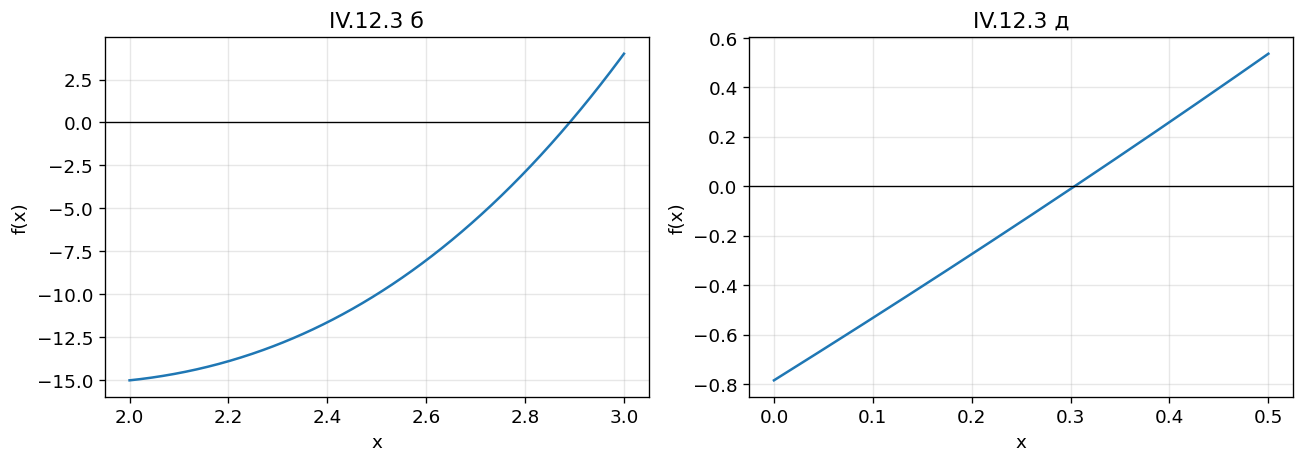

In [4]:
f2 = lambda x: np.arctan(x - 1) + 2*x
df2 = lambda x: 2 + 1/(1 + (x - 1)**2)
phi2 = lambda x: -0.5*np.arctan(x - 1)

scalar_tasks = [
    dict(name='IV.12.3 б', f=f1, df=df1, phi=phi1,
         interval=(2., 3.), x0=3., m=3., q=0.125),
    dict(name='IV.12.3 д', f=f2, df=df2, phi=phi2,
         interval=(0., 0.5), x0=0.5, m=2., q=0.5)
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, task in zip(axes, scalar_tasks):
    a, b = task['interval']
    grid = np.linspace(a, b, 400)
    ax.plot(grid, task['f'](grid))
    ax.axhline(0, color='black', lw=0.8)
    ax.set(title=task['name'], xlabel='x', ylabel='f(x)')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
scalar_rows = []
scalar_histories = {}
for task in scalar_tasks:
    f, df, phi = task['f'], task['df'], task['phi']
    reference, _ = bisection(f, *task['interval'], eps=1e-13)
    methods = ['Половинное деление', 'Простая итерация',
               'Ньютон', 'Модифицированный Ньютон']
    for method in methods:
        if method == 'Половинное деление':
            root, history = bisection(f, *task['interval'])
        else:
            root, history = scalar_iteration(
                f, df, phi, task['x0'], task['interval'], task['m'], method)
        scalar_histories[(task['name'], method)] = history
        scalar_rows.append({
            'Задача': task['name'], 'Метод': method, 'x': root,
            'Итерации': len(history)-1, '|f(x)|': abs(f(root)),
            'Оценка ошибки': history[-1],
            'Ошибка относительно проверки': abs(root-reference)
        })
scalar_table = pd.DataFrame(scalar_rows)
display(scalar_table)

,Задача,Метод,x,Итерации,|f(x)|,Оценка ошибки,Ошибка относительно проверки
0,IV.12.3 б,Половинное деление,2.8901453838,26,6.9988146834e-08,7.4505805969e-09,2.0663151190e-09
1,IV.12.3 б,Простая итерация,2.8901453858,5,1.5326655500e-09,5.1088851668e-10,4.5297987583e-11
2,IV.12.3 б,Ньютон,2.8901453867,3,2.8323357881e-08,9.4411192938e-09,8.3614359880e-10
3,IV.12.3 б,Модифицированный Ньютон,2.8901453865,9,2.1256621352e-08,7.0855404507e-09,6.2751226437e-10
4,IV.12.3 д,Половинное деление,0.3040136024,25,1.5622042771e-08,7.4505805969e-09,5.8428781813e-09
5,IV.12.3 д,Простая итерация,0.3040136023,16,1.5334144621e-08,7.6670723104e-09,5.7351993155e-09
6,IV.12.3 д,Ньютон,0.3040135966,3,1.7017498521e-12,8.5087492607e-13,6.0274008007e-13
7,IV.12.3 д,Модифицированный Ньютон,0.3040135974,6,2.1893172830e-09,1.0946586415e-09,8.1880846547e-10


### IV.12.4 а
$$\begin{cases}\sin(x+1)-y=1.2,\\2x+\cos y=2.\end{cases}$$
Точность по условию: $10^{-3}$. $\Phi=(1-\tfrac12\cos y,\ \sin(x+1)-1.2)$.

Рабочая область $D=[0.5,0.6]\times[-0.21,-0.19]$, $z_0=(0.55,-0.2)$: $\Phi(D)\subset D$, $\|\Phi'\|_\infty<0.11$.

Все решения лежат в $D_0=[0.5,1.5]\times[-2.2,-0.2]$, где $\Phi$ — сжатие с $q<0.802$. Поэтому решение единственно.

### IV.12.6 г
$$\begin{cases}\sin x-y=1.32,\\\cos y-x=-0.85.\end{cases}$$
Точность по условию: $10^{-5}$. $\Phi=(0.85+\cos y,\ \sin x-1.32)$.

$D=[1.7,1.85]\times[-0.4,-0.32]$, $z_0=(1.775,-0.36)$: $\Phi(D)\subset D$, $\|\Phi'\|_\infty<0.39$.

Все решения сводятся к $h(x)=x-0.85-\cos(\sin x-1.32)=0$ на $[-0.15,1.85]$. Здесь $h'>0$, а на концах разные знаки: решение одно.

### Методы для систем
Решаем $F(z)=z-\Phi(z)=0$, $J=I-\Phi'(z)$. В таблице — невязка исходной системы.

In [ ]:
phi_a = lambda z: np.array([1 - 0.5*np.cos(z[1]),
                             np.sin(z[0] + 1) - 1.2])
dphi_a = lambda z: np.array([[0., 0.5*np.sin(z[1])],
                              [np.cos(z[0] + 1), 0.]])
original_a = lambda z: np.array([np.sin(z[0]+1)-z[1]-1.2,
                                  2*z[0]+np.cos(z[1])-2])

phi_g = lambda z: np.array([0.85 + np.cos(z[1]),
                             np.sin(z[0]) - 1.32])
dphi_g = lambda z: np.array([[0., -np.sin(z[1])],
                              [np.cos(z[0]), 0.]])
original_g = lambda z: np.array([np.sin(z[0])-z[1]-1.32,
                                  np.cos(z[1])-z[0]+0.85])

system_tasks = [
    dict(name='IV.12.4 а', phi=phi_a, dphi=dphi_a, original=original_a,
         lower=np.array([0.5, -0.21]), upper=np.array([0.6, -0.19]),
         z0=np.array([0.55, -0.2]), q=0.11, required=1e-3),
    dict(name='IV.12.6 г', phi=phi_g, dphi=dphi_g, original=original_g,
         lower=np.array([1.7, -0.4]), upper=np.array([1.85, -0.32]),
         z0=np.array([1.775, -0.36]), q=0.39, required=1e-5)
]


def norm(v):
    return np.linalg.norm(v, ord=np.inf)


def system_iteration(task, method, eps=EPS):
    phi, dphi, q = task['phi'], task['dphi'], task['q']
    z = task['z0'].copy()
    J0 = np.eye(2) - dphi(z)
    history = [norm(z - phi(z)) / (1 - q)]
    for _ in range(MAX_ITER):
        if method == 'Простая итерация':
            new_z = phi(z)
        else:
            J = np.eye(2) - dphi(z) if method == 'Ньютон' else J0
            step = np.linalg.solve(J, -(z - phi(z)))
            new_z = z + step
        if (not np.all(np.isfinite(new_z))
                or np.any(new_z < task['lower'])
                or np.any(new_z > task['upper'])):
            raise RuntimeError('Итерация вышла из прямоугольника')
        z = new_z
        history.append(norm(z - phi(z)) / (1 - q))
        if history[-1] <= eps:
            return z, history
    raise RuntimeError('Метод для системы не сошёлся')

In [ ]:
system_rows = []
system_histories = {}
system_roots = {}
for task in system_tasks:
    reference, _ = system_iteration(task, 'Простая итерация', eps=1e-13)
    for method in ['Простая итерация', 'Ньютон', 'Модифицированный Ньютон']:
        root, history = system_iteration(task, method)
        system_roots[(task['name'], method)] = root
        system_histories[(task['name'], method)] = history
        system_rows.append({
            'Задача': task['name'], 'Метод': method,
            'x': root[0], 'y': root[1], 'Итерации': len(history)-1,
            'Невязка исходной системы': norm(task['original'](root)),
            'Оценка ошибки координат': history[-1],
            'Ошибка относительно проверки': norm(root-reference)
        })
system_table = pd.DataFrame(system_rows)
display(system_table)

,Задача,Метод,x,y,Итерации,Невязка исходной системы,Оценка ошибки координат,Ошибка относительно проверки
0,IV.12.4 а,Простая итерация,0.5101501515,-0.2018384158,6,1.2053292364e-08,6.7715125642e-09,5.9854524670e-09
1,IV.12.4 а,Ньютон,0.5101501575,-0.2018384154,3,1.1768364061e-14,1.3098136807e-14,2.4980018054e-14
2,IV.12.4 а,Модифицированный Ньютон,0.5101501574,-0.2018384152,4,1.5231904626e-10,1.7114505818e-10,1.5194484559e-10
3,IV.12.6 г,Простая итерация,1.7913386074,-0.3442210390,12,3.1329288053e-09,5.1359486791e-09,2.5766737632e-09
4,IV.12.6 г,Ньютон,1.7913386100,-0.3442210364,3,1.1102230246e-16,3.6400754906e-16,2.5979218776e-14
5,IV.12.6 г,Модифицированный Ньютон,1.7913386094,-0.3442210369,4,6.3261285099e-10,1.0370704295e-09,5.7777782558e-10


### Проверка модифицированного Ньютона
Для $T(z)=z-J_0^{-1}F(z)$ проверяем сжатие и сохранение прямоугольника:
$$|T'|\leq B=|J_0^{-1}|M,\quad\|B\|_\infty<1,\quad|T(z_0)-z_0|+Br\leq r.$$
$M$ — границы изменения $\Phi'$, $r$ — полуширины. В этих задачах элементы $\Phi'$ монотонны: достаточно углов области.

In [8]:
modified_checks = []
for task in system_tasks:
    z0 = task['z0']
    A0 = task['dphi'](z0)
    corners = [np.array([x, y]) for x in [task['lower'][0], task['upper'][0]]
               for y in [task['lower'][1], task['upper'][1]]]
    M = np.max([np.abs(task['dphi'](z)-A0) for z in corners], axis=0)
    J0 = np.eye(2) - A0
    B = np.abs(np.linalg.inv(J0)) @ M
    r = (task['upper']-task['lower'])/2
    first_step = np.linalg.solve(J0, -(z0-task['phi'](z0)))
    invariant = np.all(np.abs(first_step)+B@r <= r)
    modified_checks.append({'Задача': task['name'], 'Верхняя оценка q': norm(B),
                            'Прямоугольник сохраняется': bool(invariant)})
    assert norm(B) < 1 and invariant
    assert np.allclose(z0, (task['lower']+task['upper'])/2)
display(pd.DataFrame(modified_checks))

,Задача,Верхняя оценка q,Прямоугольник сохраняется
0,IV.12.4 а,0.0499930852,True
1,IV.12.6 г,0.0761497009,True


### Кривые систем и сходимость

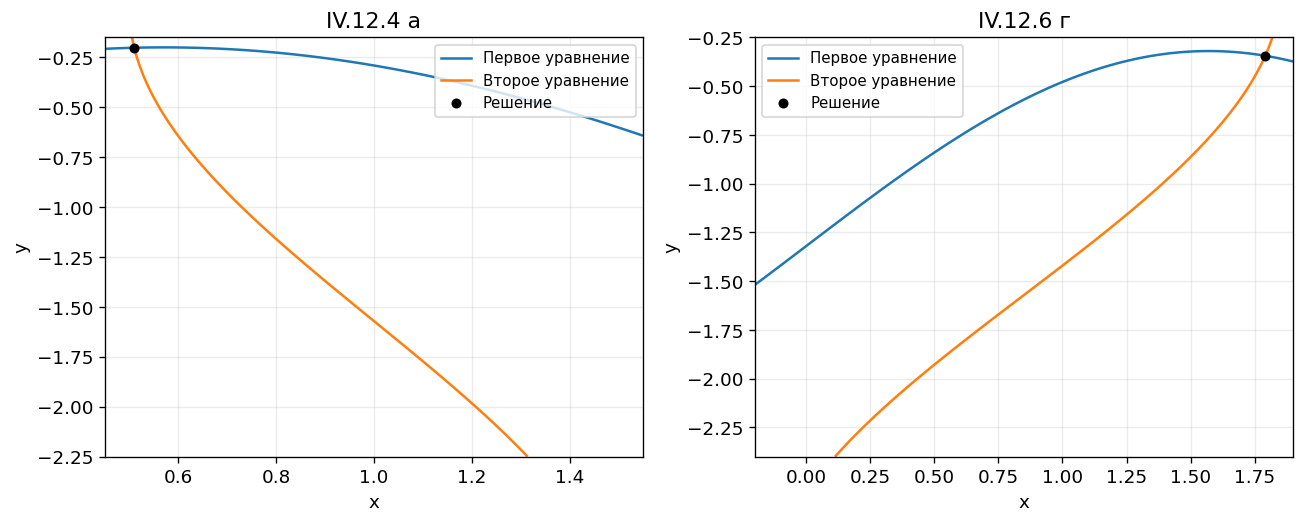

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_domains = [(0.45, 1.55, -2.25, -0.15), (-0.2, 1.9, -2.4, -0.25)]
for ax, task, domain in zip(axes, system_tasks, plot_domains):
    xmin, xmax, ymin, ymax = domain
    X, Y = np.meshgrid(np.linspace(xmin, xmax, 500),
                       np.linspace(ymin, ymax, 500))
    Z = task['original']([X, Y])
    ax.contour(X, Y, Z[0], levels=[0], colors=['tab:blue'])
    ax.contour(X, Y, Z[1], levels=[0], colors=['tab:orange'])
    root = system_roots[(task['name'], 'Ньютон')]
    ax.plot([], [], color='tab:blue', label='Первое уравнение')
    ax.plot([], [], color='tab:orange', label='Второе уравнение')
    ax.plot(*root, 'ko', ms=5, label='Решение')
    ax.set(title=task['name'], xlabel='x', ylabel='y')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

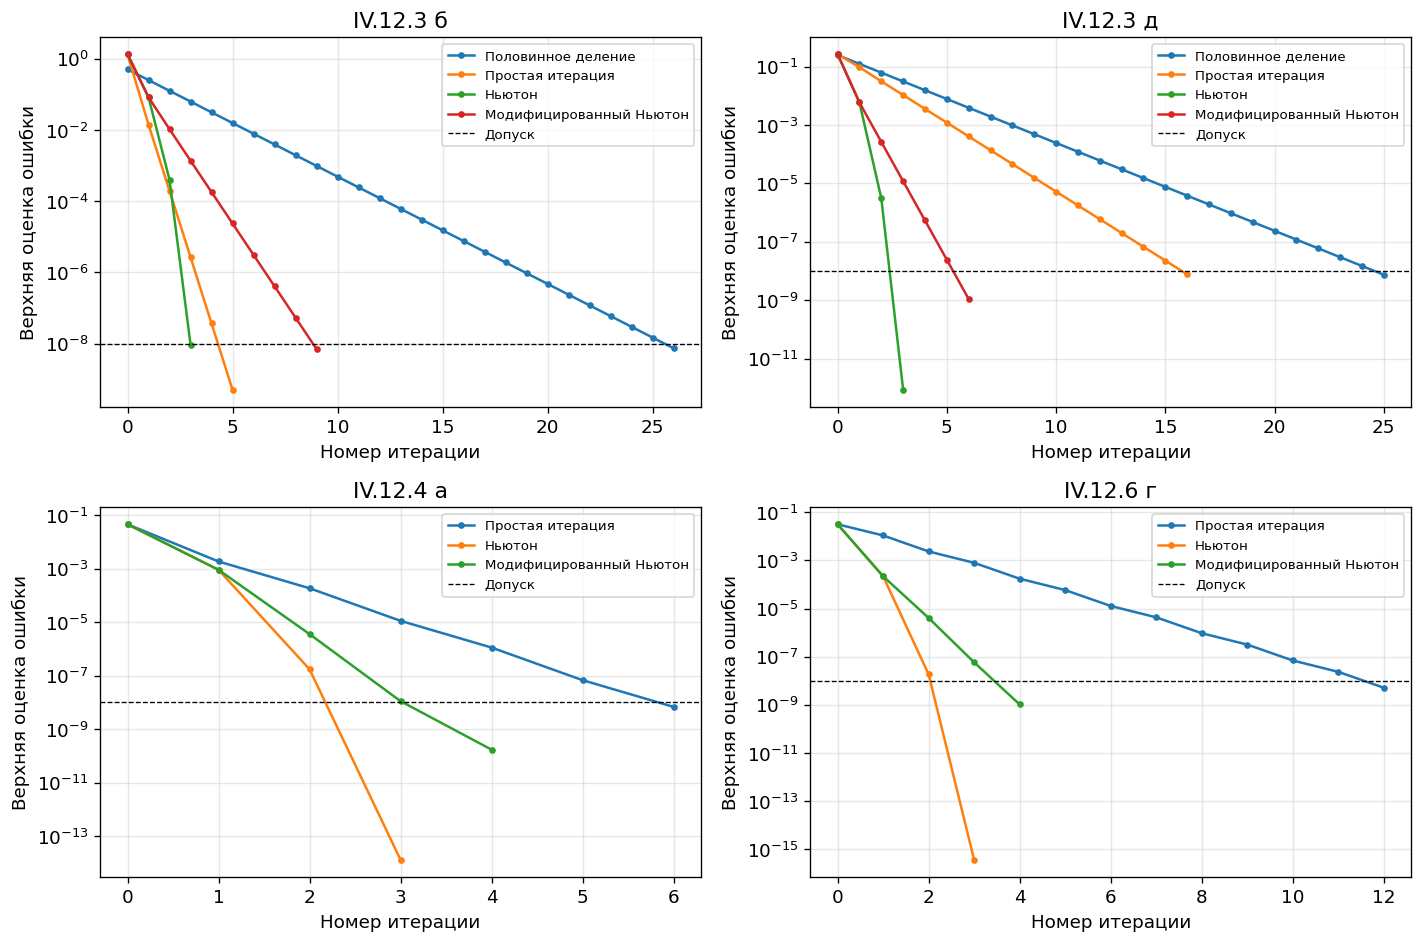

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
all_names = [task['name'] for task in scalar_tasks + system_tasks]
for ax, name in zip(axes.flat, all_names):
    histories = scalar_histories if name.startswith('IV.12.3') else system_histories
    for (task_name, method), history in histories.items():
        if task_name == name:
            ax.semilogy(range(len(history)), np.maximum(history, 1e-16),
                        marker='.', label=method)
    ax.axhline(EPS, color='black', ls='--', lw=0.8, label='Допуск')
    ax.set(title=name, xlabel='Номер итерации', ylabel='Верхняя оценка ошибки')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Ответы и сравнение методов

In [11]:
for task in scalar_tasks:
    row = scalar_table[(scalar_table['Задача'] == task['name'])
                       & (scalar_table['Метод'] == 'Ньютон')].iloc[0]
    print(f"{task['name']}: x = {row['x']:.6f}")
for task, digits in zip(system_tasks, [3, 5]):
    root = system_roots[(task['name'], 'Ньютон')]
    print(f"{task['name']}: x = {root[0]:.{digits}f}, y = {root[1]:.{digits}f}")

# Проверка точности всех методов.
assert (scalar_table['Оценка ошибки'] <= EPS).all()
assert (system_table['Оценка ошибки координат'] <= EPS).all()
assert (scalar_table['Ошибка относительно проверки'] <= EPS + 2e-13).all()
assert (system_table['Ошибка относительно проверки'] <= EPS + 2e-13).all()
assert len(scalar_table) == 8 and len(system_table) == 6
print('Все 14 расчётов прошли проверку точности.')

counts = pd.concat([scalar_table, system_table], ignore_index=True)
display(counts.pivot(index='Задача', columns='Метод', values='Итерации')
        .fillna('—'))

IV.12.3 б: x = 2.890145
IV.12.3 д: x = 0.304014
IV.12.4 а: x = 0.510, y = -0.202
IV.12.6 г: x = 1.79134, y = -0.34422
Все 14 расчётов прошли проверку точности.


Метод,Модифицированный Ньютон,Ньютон,Половинное деление,Простая итерация
Задача,,,,
IV.12.3 б,9.0,3.0,26.0,5.0
IV.12.3 д,6.0,3.0,25.0,16.0
IV.12.4 а,4.0,3.0,—,6.0
IV.12.6 г,4.0,3.0,—,12.0


**Вывод:** все методы достигли заданной точности и дали согласующиеся ответы. Ньютон потребовал 3 шага в каждой задаче; число шагов остальных методов зависит от выбранной итерационной формы.